<div style="background-color: darkred; padding: 10px; color: white;">

# Image Denoising with BM4D

</div>

### Imports

In [1]:
from bm4d import bm4d
from numcodecs import blosc
from time import time

import numpy as np
import os

from aind_exaspim_image_compression.utils import img_util, util

/opt/conda/lib/python3.10/site-packages/google/api_core/_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.12) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


### Subroutines

In [2]:
def sample_random_patch(arr, patch_shape):
    # Extract shapes
    z, y, x = arr.shape[-3:]
    pz, py, px = patch_shape

    # Sample location
    rng = np.random.default_rng()
    z0 = rng.integers(0, z - pz + 1)
    y0 = rng.integers(0, y - py + 1)
    x0 = rng.integers(0, x - px + 1)
    slices = img_util.get_slices((z0, y0, x0), patch_shape)

    return arr[(0, 0, *slices)]

### Initializations

In [3]:
# Image compressor
codec = blosc.Blosc(cname="zstd", clevel=6, shuffle=blosc.SHUFFLE)

# Parameters
patch_shape = (64, 64, 64)
sigma = 24

# Paths
img_prefixes_path = "/data/exaspim_image_prefixes.json"
img_prefixes = util.read_json(img_prefixes_path)
print("# ExaSPIM Images:", len(img_prefixes))

# ExaSPIM Images: 65


### BM4D Denoising

Brain ID: 709221
Runtime: 5.11 seconds
Original Compression Ratio: 3.69
Denoised Compression Ratio: 13.19


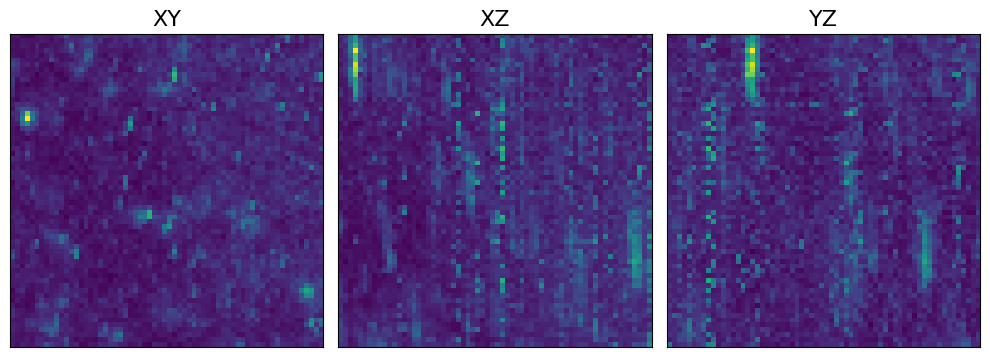

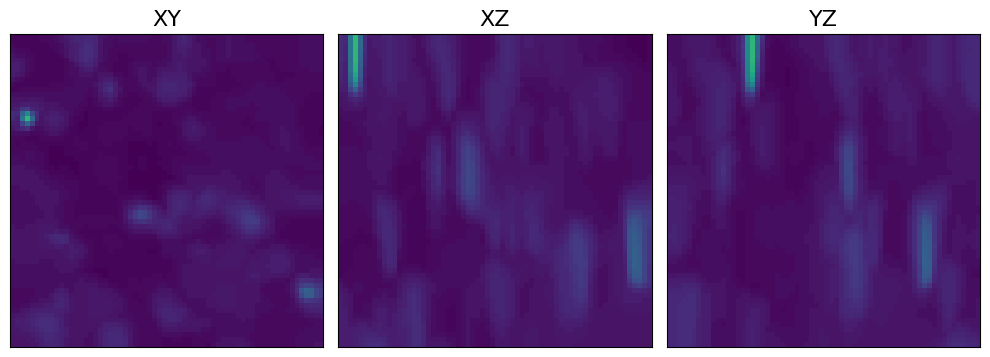

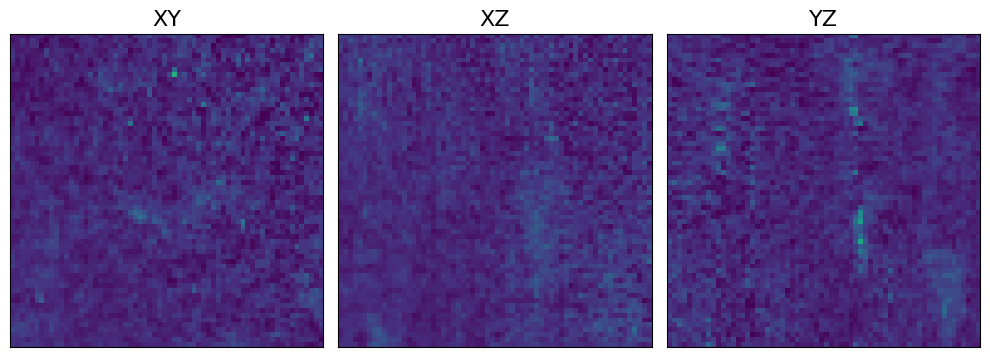

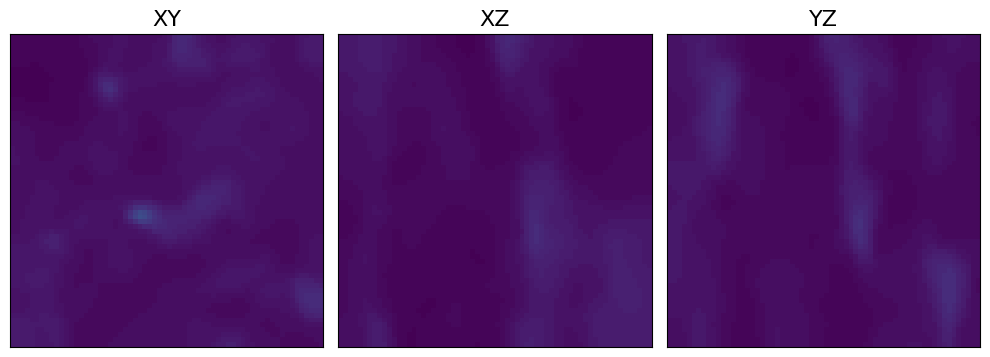

In [24]:
# Sample image
brain_id = util.sample_once(img_prefixes.keys())
img_path = os.path.join(img_prefixes[brain_id], "0")
img = img_util.read(img_path)
print("Brain ID:", brain_id)

# Get subpatch
patch = sample_random_patch(img, patch_shape)

# BM4D Denoising via STD
t0 = time()
denoised = bm4d(patch, sigma).astype(np.uint16)
print(f"Runtime: {time() - t0:.2f} seconds")

# Report compression ratios
print("Original Compression Ratio:", img_util.compute_cratio(patch, codec))
print("Denoised Compression Ratio:", img_util.compute_cratio(denoised, codec))

# Visualize results
vmax = patch.max()
img_util.plot_mips(patch, vmax=vmax)
img_util.plot_mips(denoised, vmax=vmax)

img_util.plot_slices(patch, vmax=vmax)
img_util.plot_slices(denoised, vmax=vmax)